# TP6 - Agrupamiento: Proyecto de Análisis de Conversación de Mensajería
Materia: Diseño de Bases de Datos II  
Carrera: Ingeniería en Informática - Universidad de Mendoza  
Alumno: Francisco Rodeles  

## Cargar datos
- Exportar una conversación personal o grupal de Whastapp o Telegram en un formato adecuado (JSON, CSV, etc), no exportar audios, archivos multimedia, etc
- Importar archivo y convertirlo en dataframe
- Obtener y graficar los siguientes datos. Elegir el gráfico que mejor represente los datos

In [1]:
import pandas as pd
# Importar librería de JSON
import json
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

# Leer archivo JSON que ya venía configurado en el práctico
with open('../data/chattelegramdbdII.json', 'r', encoding='utf-8') as file:
    # Cargar contenido de JSON en diccionario
    data = json.load(file)

# Convertir JSON en dataframe
df = pd.DataFrame(data["messages"])
df

,id,type,date,date_unixtime,actor,actor_id,action,title,members,text,...,edited,edited_unixtime,from,from_id,reactions,file,file_name,mime_type,reply_to_message_id,thumbnail
0,-999962624,service,2024-08-12T20:41:19,1723506079,Gabriel Arenas 🇦🇷,user192620519,create_group,Diseño Base Datos II - 2024,"[Gabriel Arenas 🇦🇷, Eliel Mato, Dolores Herrer...",,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,-999962623,service,2024-08-12T20:41:53,1723506113,Gabriel Arenas 🇦🇷,user192620519,edit_group_photo,NaN,NaN,,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,-999962622,service,2024-08-12T20:43:16,1723506196,Gabriel Arenas 🇦🇷,user192620519,migrate_to_supergroup,NaN,NaN,,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,1,service,2024-08-12T20:43:15,1723506195,Diseño Base Datos II - 2024,channel2246863389,migrate_from_group,Diseño Base Datos II - 2024,NaN,,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2,service,2024-08-12T23:17:55,1723515475,Facu Lucero,user512408504,join_group_by_link,NaN,NaN,,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
79,78,message,2024-10-07T11:17:00,1728310620,NaN,NaN,NaN,NaN,NaN,Dale profe no hay problema,...,NaN,NaN,Facu Merino,user1445938666,NaN,NaN,NaN,NaN,NaN,NaN
80,79,message,2024-10-07T16:55:00,1728330900,NaN,NaN,NaN,NaN,NaN,Chicos arrancamos 17:15 paso link,...,NaN,NaN,Gabriel Arenas 🇦🇷,user192620519,NaN,NaN,NaN,NaN,NaN,NaN
81,80,message,2024-10-07T16:55:10,1728330910,NaN,NaN,NaN,NaN,NaN,"[Clase DBD II 07-10-2024\nLunes, 7 de octubre ...",...,NaN,NaN,Gabriel Arenas 🇦🇷,user192620519,NaN,NaN,NaN,NaN,NaN,NaN
82,81,message,2024-10-14T15:59:13,1728932353,NaN,NaN,NaN,NaN,NaN,"Hola chicos, 16:30 nos vemos en la facu",...,NaN,NaN,Gabriel Arenas 🇦🇷,user192620519,NaN,NaN,NaN,NaN,NaN,NaN


### Preparación de columnas para agrupamiento

Antes de calcular las métricas se convierte la columna date a tipo datetime, se filtran los mensajes de conversación (type == message, ya que los 7 registros de tipo service corresponden a eventos del sistema como creación del grupo o cambio de foto) y se extrae el texto plano para contar la cantidad de palabras de cada mensaje.

In [2]:
# Convertir caracteres a fecha
df['date'] = pd.to_datetime(df['date'], format="%Y-%m-%dT%H:%M:%S")

# Filtrar los mensajes enviados por usuarios (descartando notificaciones de servicio sin autor en 'from')
df_msg = df[df['type'] == 'message'].copy()

# Extraer texto plano cuando 'text' contiene listas con enlaces o menciones
def obtener_texto_plano(valor):
    if isinstance(valor, str):
        return valor
    elif isinstance(valor, list):
        partes = []
        for item in valor:
            if isinstance(item, str):
                partes.append(item)
            elif isinstance(item, dict):
                partes.append(str(item.get('text', '')))
        return ''.join(partes)
    return ''

df_msg['texto_plano'] = df_msg['text'].apply(obtener_texto_plano)
df_msg['cant_palabras'] = df_msg['texto_plano'].apply(lambda s: len(s.split()))

# Columnas auxiliares de fecha y hora
df_msg['hora'] = df_msg['date'].dt.hour
df_msg['dia_semana_num'] = df_msg['date'].dt.weekday
dias_semana = {0: 'Lunes', 1: 'Martes', 2: 'Miércoles', 3: 'Jueves', 4: 'Viernes', 5: 'Sábado', 6: 'Domingo'}
df_msg['dia_semana'] = df_msg['dia_semana_num'].map(dias_semana)

print(f"Total de registros en el archivo: {len(df)} | Mensajes de usuarios: {len(df_msg)}")
df_msg[['id', 'date', 'from', 'texto_plano', 'cant_palabras', 'hora', 'dia_semana']].head()

Total de registros en el archivo: 84 | Mensajes de usuarios: 77


,id,date,from,texto_plano,cant_palabras,hora,dia_semana
5,3,2024-08-19 16:37:12,Gabriel Arenas 🇦🇷,"Hola chicos voy en camino, me demoro voy en taxi",10,16,Lunes
7,5,2024-08-19 17:05:14,Gabriel Arenas 🇦🇷,Les dejo el select para armar la vista de extr...,17,17,Lunes
8,6,2024-08-19 17:05:21,Gabriel Arenas 🇦🇷,"select 'LOCAL' origen_dato,\n rt.rental_...",213,17,Lunes
9,7,2024-08-19 18:15:43,Facu Lucero,,0,18,Lunes
10,8,2024-08-19 18:34:49,Gabriel Arenas 🇦🇷,---------------------------\nTrabajo Práctico ...,65,18,Lunes


### Cantidad de mensajes enviados por cada usuario

In [3]:
mensajes_usuario = (
    df_msg.groupby('from', as_index=False)
    .agg(cantidad_mensajes=('id', 'count'))
    .sort_values('cantidad_mensajes', ascending=False)
    .reset_index(drop=True)
)
display(mensajes_usuario)

,from,cantidad_mensajes
0,Gabriel Arenas 🇦🇷,59
1,Facu Lucero,12
2,Matias Vilches Bru,2
3,Facu Merino,2
4,Eliel Mato,1
5,Facu Mendez,1


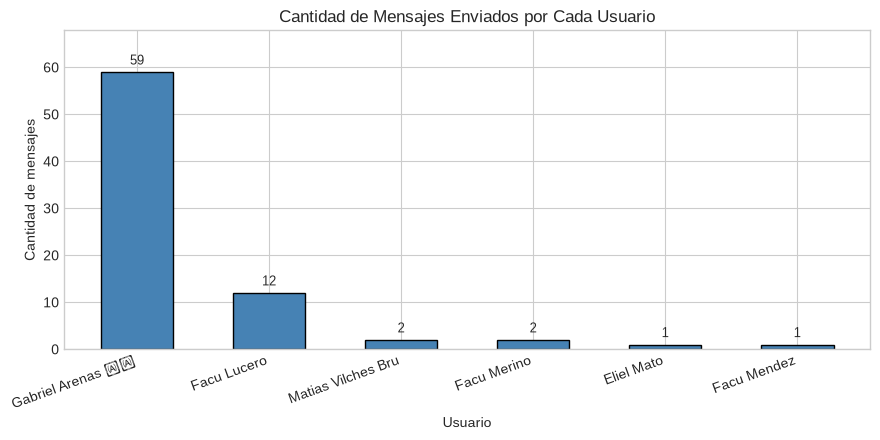

In [4]:
plt.figure(figsize=(9, 4.5))
barras = plt.bar(mensajes_usuario['from'], mensajes_usuario['cantidad_mensajes'], color='steelblue', edgecolor='black', width=0.55)
plt.xlabel('Usuario')
plt.ylabel('Cantidad de mensajes')
plt.title('Cantidad de Mensajes Enviados por Cada Usuario')
plt.xticks(rotation=20, ha='right')
plt.ylim(0, mensajes_usuario['cantidad_mensajes'].max() * 1.15)

for b in barras:
    h = b.get_height()
    plt.text(b.get_x() + b.get_width()/2, h + 1, f"{int(h)}", ha='center', va='bottom', fontsize=9.5)

plt.tight_layout()
plt.show()

### Promedio de palabras utilizadas por mensaje por cada usuario

In [5]:
promedio_palabras_usuario = (
    df_msg.groupby('from', as_index=False)
    .agg(promedio_palabras=('cant_palabras', 'mean'))
    .sort_values('promedio_palabras', ascending=False)
    .reset_index(drop=True)
)
promedio_palabras_usuario['promedio_palabras'] = promedio_palabras_usuario['promedio_palabras'].round(2)
display(promedio_palabras_usuario)

,from,promedio_palabras
0,Gabriel Arenas 🇦🇷,17.90
1,Facu Mendez,11.00
2,Eliel Mato,6.00
3,Facu Merino,5.50
4,Facu Lucero,4.67
5,Matias Vilches Bru,2.00


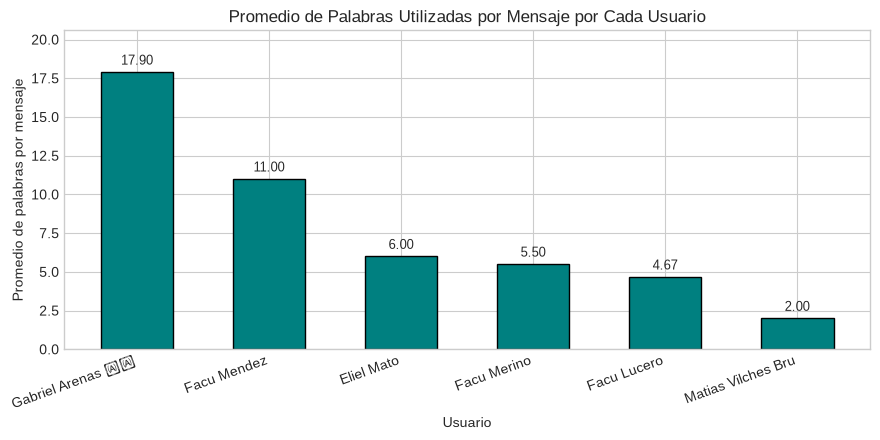

In [6]:
plt.figure(figsize=(9, 4.5))
barras = plt.bar(promedio_palabras_usuario['from'], promedio_palabras_usuario['promedio_palabras'], color='teal', edgecolor='black', width=0.55)
plt.xlabel('Usuario')
plt.ylabel('Promedio de palabras por mensaje')
plt.title('Promedio de Palabras Utilizadas por Mensaje por Cada Usuario')
plt.xticks(rotation=20, ha='right')
plt.ylim(0, promedio_palabras_usuario['promedio_palabras'].max() * 1.15)

for b in barras:
    h = b.get_height()
    plt.text(b.get_x() + b.get_width()/2, h + 0.3, f"{h:.2f}", ha='center', va='bottom', fontsize=9.5)

plt.tight_layout()
plt.show()

### Porcentaje de mensajes enviados por cada usuario

In [7]:
mensajes_usuario['porcentaje'] = (mensajes_usuario['cantidad_mensajes'] / len(df_msg) * 100).round(2)
display(mensajes_usuario)

,from,cantidad_mensajes,porcentaje
0,Gabriel Arenas 🇦🇷,59,76.62
1,Facu Lucero,12,15.58
2,Matias Vilches Bru,2,2.60
3,Facu Merino,2,2.60
4,Eliel Mato,1,1.30
5,Facu Mendez,1,1.30


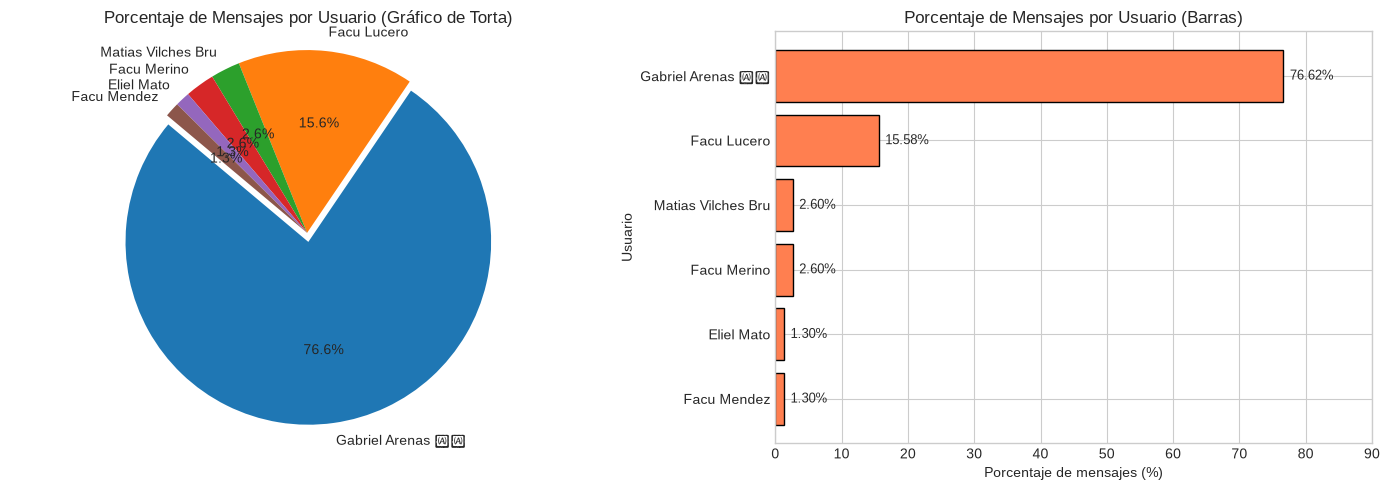

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Gráfico de torta
explode = [0.05] + [0] * (len(mensajes_usuario) - 1)
axes[0].pie(
    mensajes_usuario['porcentaje'],
    labels=mensajes_usuario['from'],
    autopct='%1.1f%%',
    startangle=140,
    explode=explode
)
axes[0].set_title('Porcentaje de Mensajes por Usuario (Gráfico de Torta)')
axes[0].axis('equal')

# Gráfico de barras horizontales para leer con precisión los porcentajes chicos
orden_asc = mensajes_usuario.sort_values('porcentaje', ascending=True)
barras_p = axes[1].barh(orden_asc['from'], orden_asc['porcentaje'], color='coral', edgecolor='black')
axes[1].set_xlabel('Porcentaje de mensajes (%)')
axes[1].set_ylabel('Usuario')
axes[1].set_title('Porcentaje de Mensajes por Usuario (Barras)')
axes[1].set_xlim(0, 90)

for b in barras_p:
    w = b.get_width()
    axes[1].text(w + 1, b.get_y() + b.get_height()/2, f"{w:.2f}%", va='center', ha='left', fontsize=9)

plt.tight_layout()
plt.show()

### Frecuencia de envío de mensaje dependiendo la hora del día

In [9]:
frecuencia_hora = (
    df_msg.groupby('hora', as_index=False)
    .agg(cantidad_mensajes=('id', 'count'))
    .sort_values('hora')
)
display(frecuencia_hora)

,hora,cantidad_mensajes
0,1,5
1,9,2
2,10,2
3,11,6
4,12,8
5,13,4
6,14,1
7,15,1
8,16,7
9,17,28


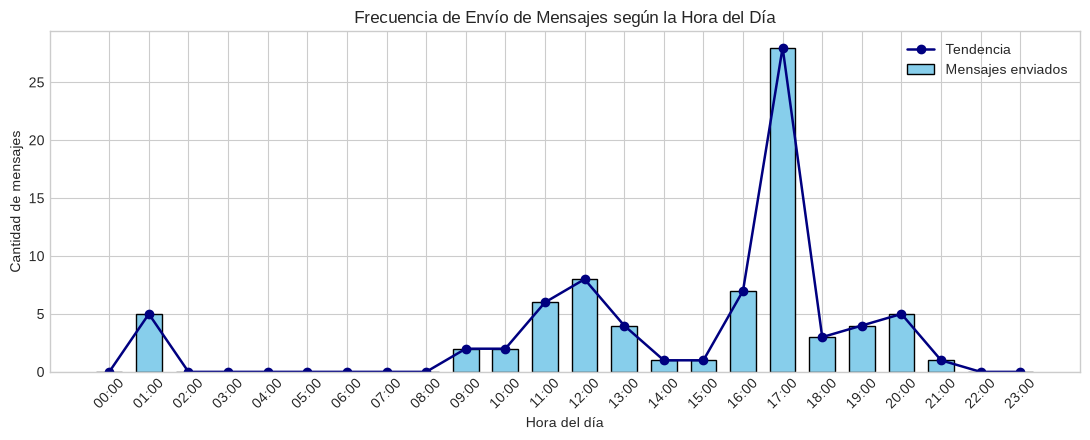

In [10]:
# Completar las 24 horas del día para visualizar también las horas sin actividad
horas_completas = pd.DataFrame({'hora': range(24)}).merge(frecuencia_hora, on='hora', how='left').fillna(0)

plt.figure(figsize=(11, 4.5))
plt.bar(horas_completas['hora'], horas_completas['cantidad_mensajes'], color='skyblue', edgecolor='black', width=0.65, label='Mensajes enviados')
plt.plot(horas_completas['hora'], horas_completas['cantidad_mensajes'], color='navy', marker='o', linewidth=1.8, label='Tendencia')
plt.xticks(range(24), [f"{h:02d}:00" for h in range(24)], rotation=45)
plt.xlabel('Hora del día')
plt.ylabel('Cantidad de mensajes')
plt.title('Frecuencia de Envío de Mensajes según la Hora del Día')
plt.legend()
plt.tight_layout()
plt.show()

### Frecuencia de envío de mensaje dependiendo del día de la semana

In [11]:
frecuencia_dia = (
    df_msg.groupby(['dia_semana_num', 'dia_semana'], as_index=False)
    .agg(cantidad_mensajes=('id', 'count'))
    .sort_values('dia_semana_num')
)
display(frecuencia_dia[['dia_semana', 'cantidad_mensajes']])

,dia_semana,cantidad_mensajes
0,Lunes,64
1,Martes,11
2,Miércoles,2


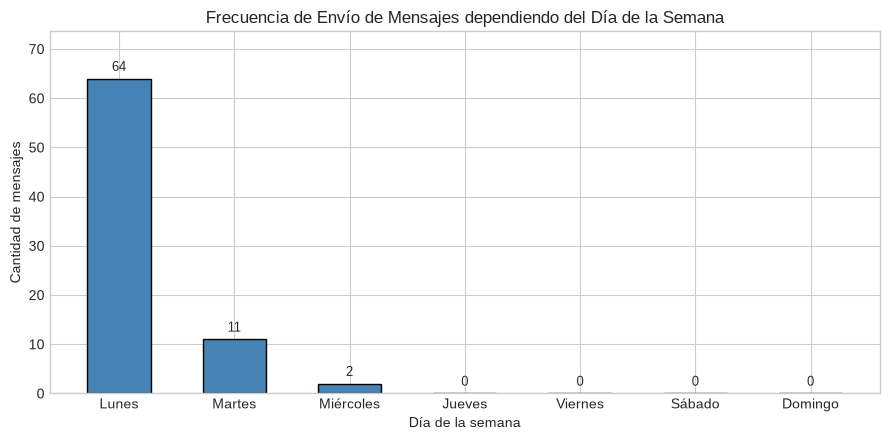

In [12]:
# Mostrar los 7 días de la semana ordenados de lunes a domingo
dias_completos = pd.DataFrame({
    'dia_semana_num': range(7),
    'dia_semana': [dias_semana[i] for i in range(7)]
}).merge(frecuencia_dia[['dia_semana_num', 'cantidad_mensajes']], on='dia_semana_num', how='left').fillna(0)

plt.figure(figsize=(9, 4.5))
barras_d = plt.bar(dias_completos['dia_semana'], dias_completos['cantidad_mensajes'], color='steelblue', edgecolor='black', width=0.55)
plt.xlabel('Día de la semana')
plt.ylabel('Cantidad de mensajes')
plt.title('Frecuencia de Envío de Mensajes dependiendo del Día de la Semana')
plt.ylim(0, dias_completos['cantidad_mensajes'].max() * 1.15)

for b in barras_d:
    h = b.get_height()
    plt.text(b.get_x() + b.get_width()/2, h + 1, f"{int(h)}", ha='center', va='bottom', fontsize=9.5)

plt.tight_layout()
plt.show()

### Hora del día preferida por cada usuario para enviar mensajes

In [13]:
hora_preferida = (
    df_msg.groupby('from', as_index=False)
    .agg(
        hora_preferida=('hora', lambda x: int(x.mode().iloc[0])),
        cantidad_mensajes=('id', 'count')
    )
    .sort_values('hora_preferida')
    .reset_index(drop=True)
)
display(hora_preferida)

,from,hora_preferida,cantidad_mensajes
0,Facu Lucero,1,12
1,Facu Merino,11,2
2,Eliel Mato,13,1
3,Matias Vilches Bru,14,2
4,Facu Mendez,17,1
5,Gabriel Arenas 🇦🇷,17,59


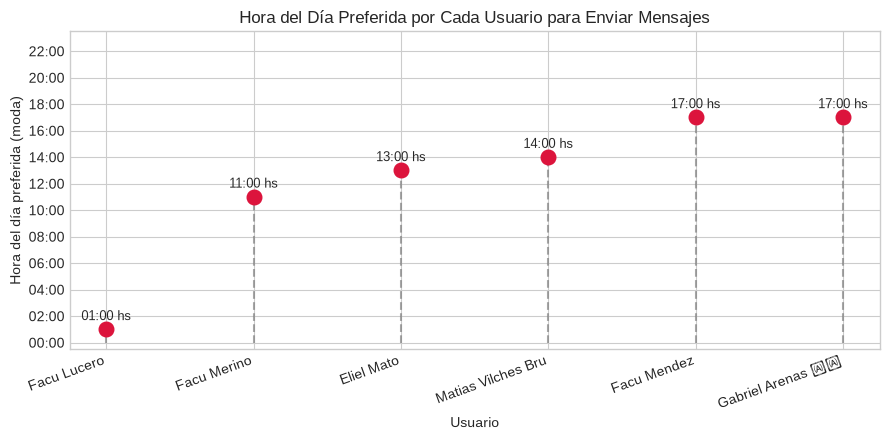

In [14]:
plt.figure(figsize=(9, 4.5))
plt.scatter(hora_preferida['from'], hora_preferida['hora_preferida'], s=110, color='crimson', zorder=3)
plt.vlines(hora_preferida['from'], ymin=0, ymax=hora_preferida['hora_preferida'], color='gray', linestyle='--', alpha=0.7)
plt.yticks(range(0, 24, 2), [f"{h:02d}:00" for h in range(0, 24, 2)])
plt.ylim(-0.5, 23.5)
plt.xlabel('Usuario')
plt.ylabel('Hora del día preferida (moda)')
plt.title('Hora del Día Preferida por Cada Usuario para Enviar Mensajes')
plt.xticks(rotation=20, ha='right')

for i, row in hora_preferida.iterrows():
    plt.text(row['from'], row['hora_preferida'] + 0.7, f"{row['hora_preferida']:02d}:00 hs", ha='center', fontsize=9)

plt.tight_layout()
plt.show()

### Día de la semana preferida por cada usuario para enviar mensajes

In [15]:
dia_preferido = (
    df_msg.groupby('from', as_index=False)
    .agg(
        dia_num_preferido=('dia_semana_num', lambda x: int(x.mode().iloc[0])),
        dia_preferido=('dia_semana', lambda x: x.mode().iloc[0]),
        cantidad_mensajes=('id', 'count')
    )
    .sort_values('cantidad_mensajes', ascending=False)
    .reset_index(drop=True)
)
display(dia_preferido[['from', 'dia_preferido', 'cantidad_mensajes']])

,from,dia_preferido,cantidad_mensajes
0,Gabriel Arenas 🇦🇷,Lunes,59
1,Facu Lucero,Lunes,12
2,Matias Vilches Bru,Lunes,2
3,Facu Merino,Lunes,2
4,Eliel Mato,Lunes,1
5,Facu Mendez,Lunes,1


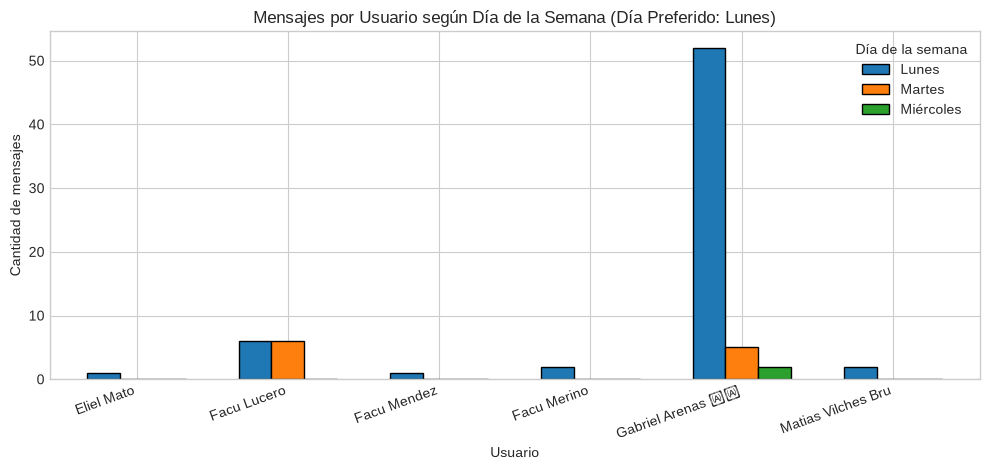

In [16]:
# Tabla cruzada de mensajes por usuario y día de la semana para visualizar por qué Lunes es la moda en todos
tabla_usuario_dia = df_msg.groupby(['from', 'dia_semana'])['id'].count().unstack(fill_value=0)
cols_presentes = [d for d in ['Lunes', 'Martes', 'Miércoles', 'Jueves', 'Viernes', 'Sábado', 'Domingo'] if d in tabla_usuario_dia.columns]
tabla_usuario_dia = tabla_usuario_dia[cols_presentes]

ax = tabla_usuario_dia.plot(kind='bar', figsize=(10, 4.8), edgecolor='black', width=0.65)
plt.xlabel('Usuario')
plt.ylabel('Cantidad de mensajes')
plt.title('Mensajes por Usuario según Día de la Semana (Día Preferido: Lunes)')
plt.xticks(rotation=20, ha='right')
plt.legend(title='Día de la semana')
plt.tight_layout()
plt.show()

### Cantidad promedio de mensajes enviados por hora para cada usuario

In [17]:
# Se agrupa por usuario y hora activa (fecha + hora) y luego se obtiene el promedio por usuario, además del promedio sobre las 24 hs del día
df_msg['fecha_hora'] = df_msg['date'].dt.floor('h')

mensajes_por_hora_activa = (
    df_msg.groupby(['from', 'fecha_hora'], as_index=False)
    .agg(mensajes_en_hora=('id', 'count'))
)

promedio_hora_usuario = (
    mensajes_por_hora_activa.groupby('from', as_index=False)
    .agg(
        promedio_por_hora_activa=('mensajes_en_hora', 'mean'),
        horas_con_actividad=('fecha_hora', 'count'),
        total_mensajes=('mensajes_en_hora', 'sum')
    )
    .sort_values('promedio_por_hora_activa', ascending=False)
    .reset_index(drop=True)
)
promedio_hora_usuario['promedio_sobre_24h'] = (promedio_hora_usuario['total_mensajes'] / 24.0).round(2)
promedio_hora_usuario['promedio_por_hora_activa'] = promedio_hora_usuario['promedio_por_hora_activa'].round(2)

display(promedio_hora_usuario)

,from,promedio_por_hora_activa,horas_con_actividad,total_mensajes,promedio_sobre_24h
0,Gabriel Arenas 🇦🇷,2.03,29,59,2.46
1,Facu Lucero,1.50,8,12,0.50
2,Eliel Mato,1.00,1,1,0.04
3,Facu Mendez,1.00,1,1,0.04
4,Facu Merino,1.00,2,2,0.08
5,Matias Vilches Bru,1.00,2,2,0.08


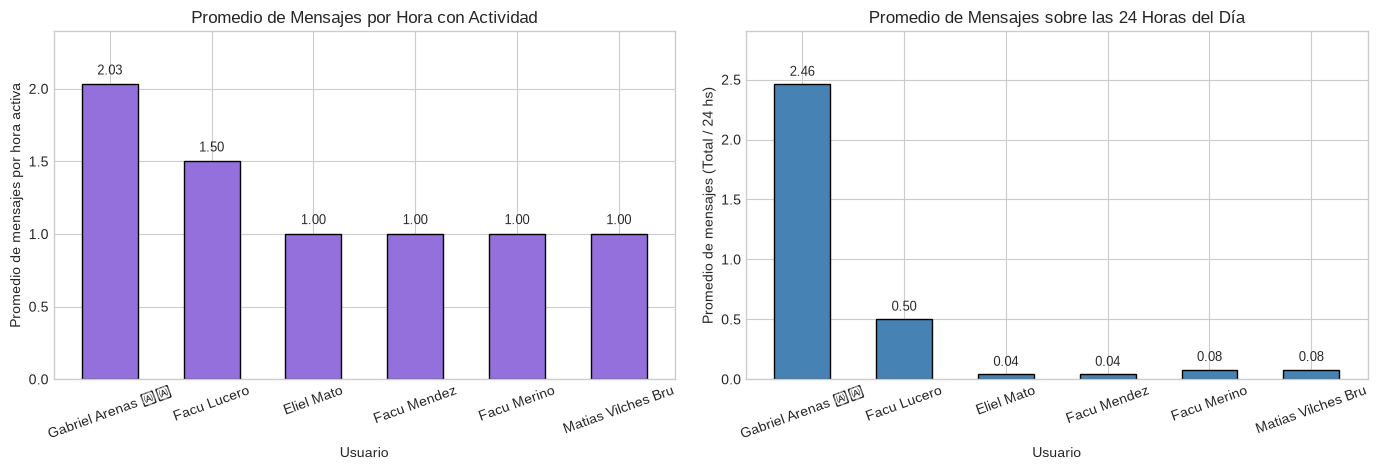

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))

barras_ha = axes[0].bar(promedio_hora_usuario['from'], promedio_hora_usuario['promedio_por_hora_activa'], color='mediumpurple', edgecolor='black', width=0.55)
axes[0].set_xlabel('Usuario')
axes[0].set_ylabel('Promedio de mensajes por hora activa')
axes[0].set_title('Promedio de Mensajes por Hora con Actividad')
axes[0].tick_params(axis='x', rotation=20)
axes[0].set_ylim(0, promedio_hora_usuario['promedio_por_hora_activa'].max() * 1.18)

for b in barras_ha:
    h = b.get_height()
    axes[0].text(b.get_x() + b.get_width()/2, h + 0.05, f"{h:.2f}", ha='center', va='bottom', fontsize=9)

barras_24 = axes[1].bar(promedio_hora_usuario['from'], promedio_hora_usuario['promedio_sobre_24h'], color='steelblue', edgecolor='black', width=0.55)
axes[1].set_xlabel('Usuario')
axes[1].set_ylabel('Promedio de mensajes (Total / 24 hs)')
axes[1].set_title('Promedio de Mensajes sobre las 24 Horas del Día')
axes[1].tick_params(axis='x', rotation=20)
axes[1].set_ylim(0, promedio_hora_usuario['promedio_sobre_24h'].max() * 1.18)

for b in barras_24:
    h = b.get_height()
    axes[1].text(b.get_x() + b.get_width()/2, h + 0.05, f"{h:.2f}", ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()

### Cantidad de usuarios promedio que envían mensaje por cada día de la semana

In [19]:
df_msg['fecha_dia'] = df_msg['date'].dt.date

usuarios_por_jornada = (
    df_msg.groupby(['fecha_dia', 'dia_semana_num', 'dia_semana'], as_index=False)
    .agg(usuarios_activos=('from', 'nunique'))
)

promedio_usuarios_dia = (
    usuarios_por_jornada.groupby(['dia_semana_num', 'dia_semana'], as_index=False)
    .agg(
        promedio_usuarios=('usuarios_activos', 'mean'),
        jornadas_con_mensajes=('fecha_dia', 'count'),
        usuarios_distintos_acumulados=('usuarios_activos', 'max')
    )
    .sort_values('dia_semana_num')
)
promedio_usuarios_dia['promedio_usuarios'] = promedio_usuarios_dia['promedio_usuarios'].round(2)
display(promedio_usuarios_dia[['dia_semana', 'promedio_usuarios', 'jornadas_con_mensajes']])

,dia_semana,promedio_usuarios,jornadas_con_mensajes
0,Lunes,2.25,8
1,Martes,1.67,3
2,Miércoles,1.00,2


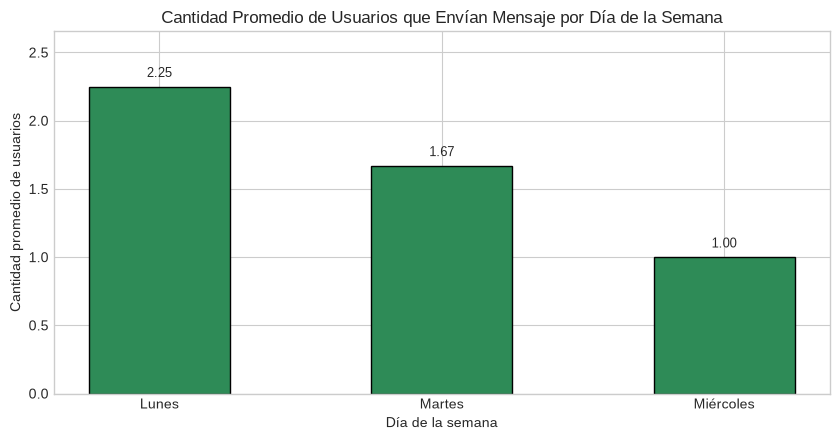

In [20]:
plt.figure(figsize=(8.5, 4.5))
barras_ud = plt.bar(promedio_usuarios_dia['dia_semana'], promedio_usuarios_dia['promedio_usuarios'], color='seagreen', edgecolor='black', width=0.5)
plt.xlabel('Día de la semana')
plt.ylabel('Cantidad promedio de usuarios')
plt.title('Cantidad Promedio de Usuarios que Envían Mensaje por Día de la Semana')
plt.ylim(0, promedio_usuarios_dia['promedio_usuarios'].max() * 1.18)

for b in barras_ud:
    h = b.get_height()
    plt.text(b.get_x() + b.get_width()/2, h + 0.05, f"{h:.2f}", ha='center', va='bottom', fontsize=9.5)

plt.tight_layout()
plt.show()

### Cantidad de mensajes envíados por mes

In [21]:
mensajes_por_mes = (
    df_msg.groupby(df_msg['date'].dt.to_period('M'))
    .agg(cantidad_mensajes=('id', 'count'))
    .reset_index()
)
mensajes_por_mes['mes_periodo'] = mensajes_por_mes['date'].astype(str)
display(mensajes_por_mes[['mes_periodo', 'cantidad_mensajes']])

,mes_periodo,cantidad_mensajes
0,2024-08,26
1,2024-09,45
2,2024-10,6


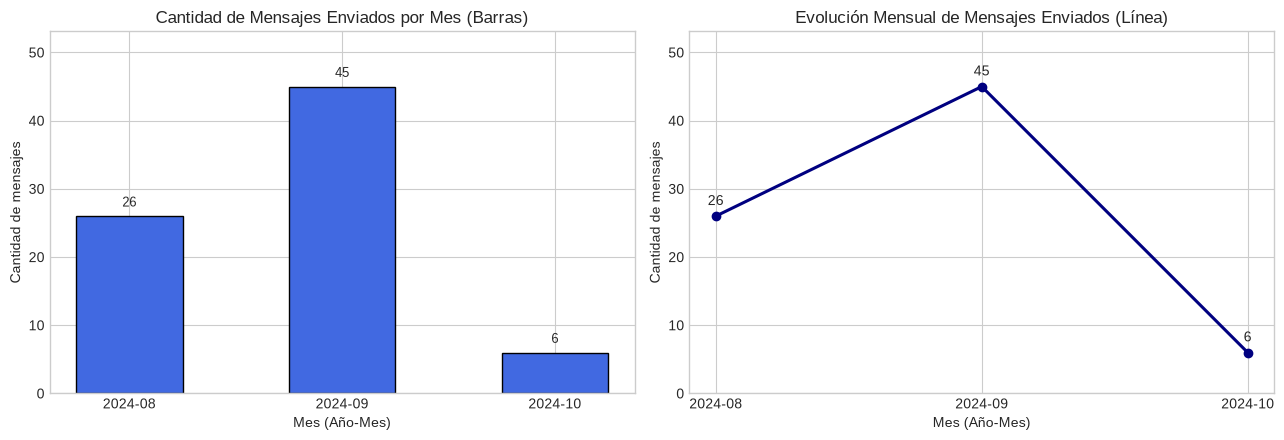

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

barras_m = axes[0].bar(mensajes_por_mes['mes_periodo'], mensajes_por_mes['cantidad_mensajes'], color='royalblue', edgecolor='black', width=0.5)
axes[0].set_xlabel('Mes (Año-Mes)')
axes[0].set_ylabel('Cantidad de mensajes')
axes[0].set_title('Cantidad de Mensajes Enviados por Mes (Barras)')
axes[0].set_ylim(0, mensajes_por_mes['cantidad_mensajes'].max() * 1.18)

for b in barras_m:
    h = b.get_height()
    axes[0].text(b.get_x() + b.get_width()/2, h + 1, f"{int(h)}", ha='center', va='bottom', fontsize=9.5)

axes[1].plot(mensajes_por_mes['mes_periodo'], mensajes_por_mes['cantidad_mensajes'], marker='o', linewidth=2.2, color='navy')
axes[1].set_xlabel('Mes (Año-Mes)')
axes[1].set_ylabel('Cantidad de mensajes')
axes[1].set_title('Evolución Mensual de Mensajes Enviados (Línea)')
axes[1].set_ylim(0, mensajes_por_mes['cantidad_mensajes'].max() * 1.18)

for i, row in mensajes_por_mes.iterrows():
    axes[1].annotate(f"{row['cantidad_mensajes']}", (row['mes_periodo'], row['cantidad_mensajes']), textcoords="offset points", xytext=(0, 8), ha='center')

plt.tight_layout()
plt.show()

### Cantidad mínima, máxima y promedio de palabras por mensaje

In [23]:
# 1. Cálculo global sobre la conversación
min_pal = df_msg['cant_palabras'].min()
max_pal = df_msg['cant_palabras'].max()
prom_pal = round(df_msg['cant_palabras'].mean(), 2)

resumen_global = pd.DataFrame({
    'Estadístico': ['Mínimo de palabras', 'Promedio de palabras', 'Máximo de palabras'],
    'Valor (todos los mensajes)': [
        min_pal,
        prom_pal,
        max_pal
    ],
    'Valor (solo mensajes con texto > 0 palabras)': [
        df_msg.loc[df_msg['cant_palabras'] > 0, 'cant_palabras'].min(),
        round(df_msg.loc[df_msg['cant_palabras'] > 0, 'cant_palabras'].mean(), 2),
        df_msg.loc[df_msg['cant_palabras'] > 0, 'cant_palabras'].max()
    ]
})
display(resumen_global)

# 2. Múltiples agregaciones (min, max, mean) agrupadas por usuario como en Agrupamiento.ipynb
palabras_stats_usuario = (
    df_msg.groupby('from', as_index=False)
    .agg(
        min_palabras=('cant_palabras', 'min'),
        promedio_palabras=('cant_palabras', 'mean'),
        max_palabras=('cant_palabras', 'max')
    )
    .sort_values('max_palabras', ascending=False)
    .reset_index(drop=True)
)
palabras_stats_usuario['promedio_palabras'] = palabras_stats_usuario['promedio_palabras'].round(2)
display(palabras_stats_usuario)

,Estadístico,Valor (todos los mensajes),Valor (solo mensajes con texto > 0 palabras)
0,Mínimo de palabras,0.00,1.00
1,Promedio de palabras,14.86,17.07
2,Máximo de palabras,219.00,219.00


,from,min_palabras,promedio_palabras,max_palabras
0,Gabriel Arenas 🇦🇷,0,17.90,219
1,Facu Lucero,0,4.67,28
2,Facu Mendez,11,11.00,11
3,Eliel Mato,6,6.00,6
4,Facu Merino,5,5.50,6
5,Matias Vilches Bru,1,2.00,3


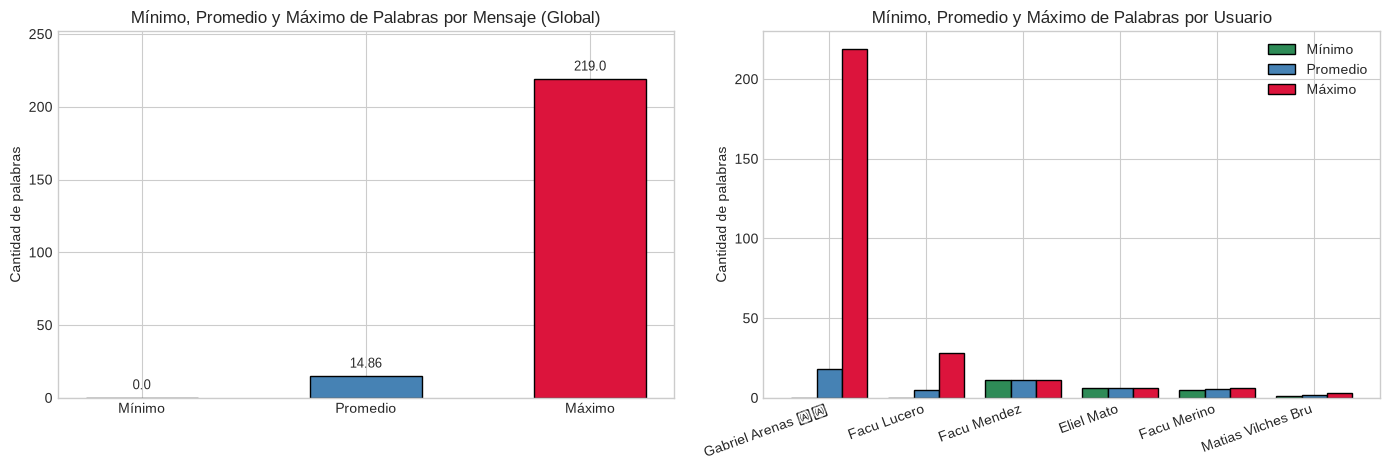

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))

# Gráfico 1: Mínimo, promedio y máximo global
etiquetas_g = ['Mínimo', 'Promedio', 'Máximo']
valores_g = [min_pal, prom_pal, max_pal]
barras_g = axes[0].bar(etiquetas_g, valores_g, color=['seagreen', 'steelblue', 'crimson'], edgecolor='black', width=0.5)
axes[0].set_ylabel('Cantidad de palabras')
axes[0].set_title('Mínimo, Promedio y Máximo de Palabras por Mensaje (Global)')
axes[0].set_ylim(0, max_pal * 1.15)

for b in barras_g:
    h = b.get_height()
    axes[0].text(b.get_x() + b.get_width()/2, h + 4, f"{h}", ha='center', va='bottom', fontsize=9.5)

# Gráfico 2: Mínimo, promedio y máximo desglosado por cada usuario
x = np.arange(len(palabras_stats_usuario))
ancho = 0.26

axes[1].bar(x - ancho, palabras_stats_usuario['min_palabras'], width=ancho, label='Mínimo', color='seagreen', edgecolor='black')
axes[1].bar(x, palabras_stats_usuario['promedio_palabras'], width=ancho, label='Promedio', color='steelblue', edgecolor='black')
axes[1].bar(x + ancho, palabras_stats_usuario['max_palabras'], width=ancho, label='Máximo', color='crimson', edgecolor='black')

axes[1].set_xticks(x)
axes[1].set_xticklabels(palabras_stats_usuario['from'], rotation=20, ha='right')
axes[1].set_ylabel('Cantidad de palabras')
axes[1].set_title('Mínimo, Promedio y Máximo de Palabras por Usuario')
axes[1].legend()

plt.tight_layout()
plt.show()